# Exploratory Data Analysis: Cryptocurrency Market Prediction

This notebook explores the two raw data sources behind the capstone before any modeling:
1. **Daily historical prices** for 24 coins (`data/coin_*.csv`) — real data, Kaggle "Cryptocurrency Historical Prices (Daily Altcoins & Bitcoin)".
2. **15-minute OHLCV** series (`data/coin_price_15min.csv`) used by the modeling notebook — currently a **synthetic placeholder**, flagged where relevant.

Follows the question-driven EDA style used in `example/1. Predictive-maintenance_exploratory_data_analysis.ipynb`: a short question as a markdown header, one focused cell to answer it.

## Standard package imports

In [1]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

matplotlib.style.use("ggplot")
%matplotlib inline
import seaborn as sns
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = "png"  # static image output: renders identically in a saved notebook, on
                                # GitHub, or live — swap to "notebook" in a live kernel for interactivity
sns.set_style("whitegrid")

## Standard functions used throughout the notebook

In [2]:
def check_null(df):
    """Percentage of missing values per column."""
    return (df.isna().sum() * 100 / len(df)).round(2)

def check_duplicate(df, subset):
    """Number of duplicate rows on the given subset of columns."""
    return df.duplicated(subset=subset).sum()

def get_missing_dates(dates, start, end, freq="D"):
    """Dates in [start, end] at the given frequency that are absent from `dates`."""
    full = pd.date_range(start, end, freq=freq)
    return full.difference(pd.DatetimeIndex(dates))

def plot_ts(series, title, ylabel, ax=None):
    ax = series.plot(figsize=(10, 3.5), title=title, ax=ax)
    ax.set_xlabel("Date"); ax.set_ylabel(ylabel)
    plt.tight_layout()
    return ax

# Part 1 — Daily prices across 24 coins (real Kaggle data)

### Data description
Each `coin_<Name>.csv` has one row per day with columns `SNo, Name, Symbol, Date, High, Low, Open, Close, Volume, Marketcap`.

In [3]:
DATA_DIR = "data"
# exclude coin_price_15min.csv (the separate intraday file used in Part 2) from the daily per-coin glob
coin_files = sorted(
    f for f in glob.glob(f"{DATA_DIR}/coin_*.csv")
    if os.path.basename(f) != "coin_price_15min.csv"
)
print(f"Found {len(coin_files)} coin files")
[os.path.basename(f) for f in coin_files]

Found 23 coin files


['coin_Aave.csv',
 'coin_BinanceCoin.csv',
 'coin_Bitcoin.csv',
 'coin_Cardano.csv',
 'coin_ChainLink.csv',
 'coin_Cosmos.csv',
 'coin_CryptocomCoin.csv',
 'coin_Dogecoin.csv',
 'coin_EOS.csv',
 'coin_Ethereum.csv',
 'coin_Iota.csv',
 'coin_Litecoin.csv',
 'coin_Monero.csv',
 'coin_NEM.csv',
 'coin_Polkadot.csv',
 'coin_Solana.csv',
 'coin_Stellar.csv',
 'coin_Tether.csv',
 'coin_Tron.csv',
 'coin_USDCoin.csv',
 'coin_Uniswap.csv',
 'coin_WrappedBitcoin.csv',
 'coin_XRP.csv']

### Load and combine all coins into one long DataFrame

In [4]:
frames = []
for path in coin_files:
    coin_df = pd.read_csv(path)
    coin_df["Date"] = pd.to_datetime(coin_df["Date"])
    frames.append(coin_df)
daily = pd.concat(frames, ignore_index=True).sort_values(["Symbol", "Date"])
print("Shape:", daily.shape)
daily.head()

Shape: (37082, 10)


,SNo,Name,Symbol,Date,High,Low,Open,Close,Volume,Marketcap
0,1,Aave,AAVE,2020-10-05 23:59:59,55.112358,49.787900,52.675035,53.219243,0.000000e+00,8.912813e+07
1,2,Aave,AAVE,2020-10-06 23:59:59,53.402270,40.734578,53.291969,42.401599,5.830915e+05,7.101144e+07
2,3,Aave,AAVE,2020-10-07 23:59:59,42.408314,35.970690,42.399947,40.083976,6.828342e+05,6.713004e+07
3,4,Aave,AAVE,2020-10-08 23:59:59,44.902511,36.696057,39.885262,43.764463,1.658817e+06,2.202651e+08
4,5,Aave,AAVE,2020-10-09 23:59:59,47.569533,43.291776,43.764463,46.817744,8.155377e+05,2.356322e+08


### How many coins, and what does one look like up close?

In [5]:
print("Unique coins:", daily['Symbol'].nunique())
daily[daily.Symbol == 'BTC'].tail()

Unique coins: 23


,SNo,Name,Symbol,Date,High,Low,Open,Close,Volume,Marketcap
4703,2987,Bitcoin,BTC,2021-07-02 23:59:59,33939.588699,32770.680780,33549.600177,33897.048590,3.872897e+10,6.354508e+11
4704,2988,Bitcoin,BTC,2021-07-03 23:59:59,34909.259899,33402.696536,33854.421362,34668.548402,2.438396e+10,6.499397e+11
4705,2989,Bitcoin,BTC,2021-07-04 23:59:59,35937.567147,34396.477458,34665.564866,35287.779766,2.492431e+10,6.615748e+11
4706,2990,Bitcoin,BTC,2021-07-05 23:59:59,35284.344430,33213.661034,35284.344430,33746.002456,2.672155e+10,6.326962e+11
4707,2991,Bitcoin,BTC,2021-07-06 23:59:59,35038.536363,33599.916169,33723.509655,34235.193451,2.650126e+10,6.418992e+11


### What date range does each coin cover?

In [6]:
coverage = daily.groupby("Symbol")["Date"].agg(["min", "max", "count"]).sort_values("min")
coverage

,min,max,count
Symbol,,,
LTC,2013-04-29 23:59:59,2021-07-06 23:59:59,2991
BTC,2013-04-29 23:59:59,2021-07-06 23:59:59,2991
XRP,2013-08-05 23:59:59,2021-07-06 23:59:59,2893
DOGE,2013-12-16 23:59:59,2021-07-06 23:59:59,2760
XMR,2014-05-22 23:59:59,2021-07-06 23:59:59,2602
XLM,2014-08-06 23:59:59,2021-07-06 23:59:59,2527
USDT,2015-02-26 23:59:59,2021-07-06 23:59:59,2318
XEM,2015-04-02 23:59:59,2021-07-06 23:59:59,2288
ETH,2015-08-08 23:59:59,2021-07-06 23:59:59,2160


Coins have very different histories — Bitcoin starts in 2013, many altcoins only have a couple of years of data.
Any cross-coin model or feature (e.g. a market-wide sentiment index) has to account for this imbalance.

### Are there missing values?

In [7]:
check_null(daily)

SNo          0.0
Name         0.0
Symbol       0.0
Date         0.0
High         0.0
Low          0.0
Open         0.0
Close        0.0
Volume       0.0
Marketcap    0.0
dtype: float64

### Are there duplicate (Symbol, Date) rows?

In [8]:
check_duplicate(daily, ["Symbol", "Date"])

np.int64(0)

### Are there missing calendar days within a coin's own coverage window? (check on Bitcoin)

In [9]:
btc = daily[daily.Symbol == "BTC"].set_index("Date").sort_index()
missing = get_missing_dates(btc.index, btc.index.min(), btc.index.max(), freq="D")
print(f"{len(missing)} missing calendar days out of {(btc.index.max()-btc.index.min()).days} in range")
missing[:5]

0 missing calendar days out of 2990 in range


DatetimeIndex([], dtype='datetime64[us]', freq='D')

### Bitcoin and Ethereum closing price over time (log scale)

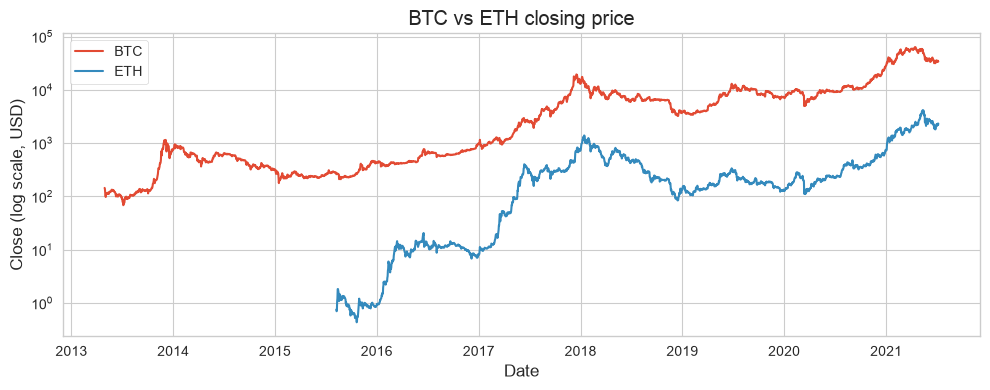

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
for sym in ["BTC", "ETH"]:
    s = daily[daily.Symbol == sym].set_index("Date")["Close"]
    ax.plot(s.index, s.values, label=sym)
ax.set_yscale("log"); ax.set_xlabel("Date"); ax.set_ylabel("Close (log scale, USD)")
ax.set_title("BTC vs ETH closing price")
ax.legend(); plt.tight_layout(); plt.show()

### Interactive candlestick view of BTC's last year (Plotly)
Static charts above don't let you zoom into a specific period — a Plotly candlestick with a range
slider does. Rendered as a static image here (`pio.renderers.default = "png"`) so it displays the
same way in this saved notebook, on GitHub, or in a live kernel; open live and switch the renderer
to `"notebook"` for full hover/zoom interactivity.

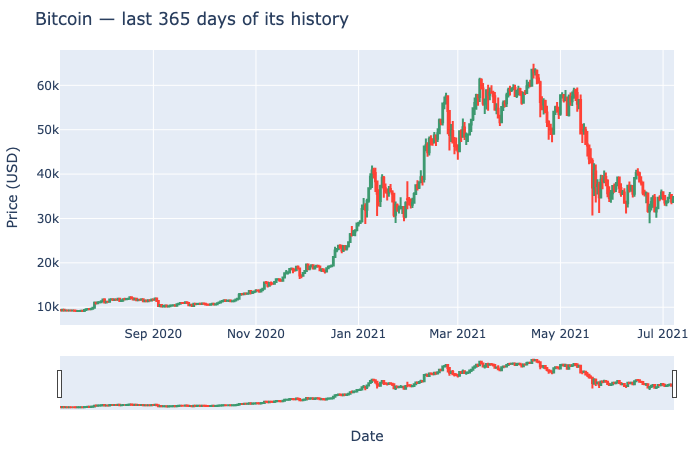

In [11]:
recent_btc = btc.tail(365)
candlestick_fig = go.Figure(data=[go.Candlestick(
    x=recent_btc.index, open=recent_btc["Open"], high=recent_btc["High"],
    low=recent_btc["Low"], close=recent_btc["Close"], name="BTC",
)])
candlestick_fig.update_layout(
    title="Bitcoin — last 365 days of its history", xaxis_title="Date", yaxis_title="Price (USD)",
    xaxis_rangeslider_visible=True, height=450, margin=dict(l=40, r=20, t=50, b=40),
)
candlestick_fig.show()

### Daily return distribution — is it fat-tailed vs. a normal curve?

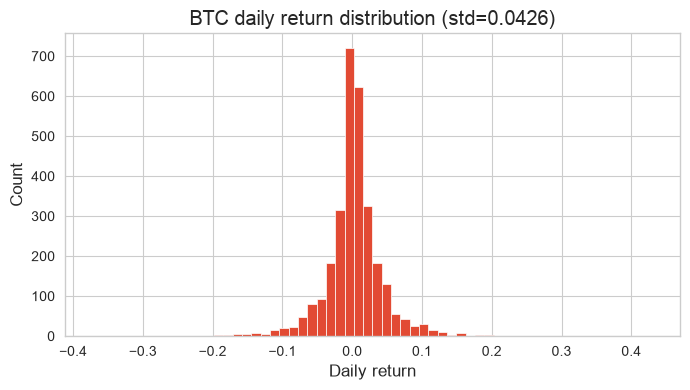

Skew: 0.244 | Kurtosis: 10.269


In [12]:
btc["ret"] = btc["Close"].pct_change()
fig, ax = plt.subplots(figsize=(7, 4))
btc["ret"].dropna().plot.hist(bins=60, ax=ax)
ax.set_xlabel("Daily return"); ax.set_ylabel("Count")
ax.set_title(f"BTC daily return distribution (std={btc['ret'].std():.4f})")
plt.tight_layout(); plt.show()
print("Skew:", btc['ret'].skew().round(3), "| Kurtosis:", btc['ret'].kurtosis().round(3))

Kurtosis well above 0 (normal) confirms the classic crypto stylised fact: **fat tails** — large moves happen far
more often than a Gaussian would predict. This motivates using tree ensembles / RNNs over a naive linear-Gaussian
model, and justifies clipping or robust-scaling outlier returns during feature engineering.

### Which coins are most volatile? (annualized std of daily returns, coins with 2+ years of history)

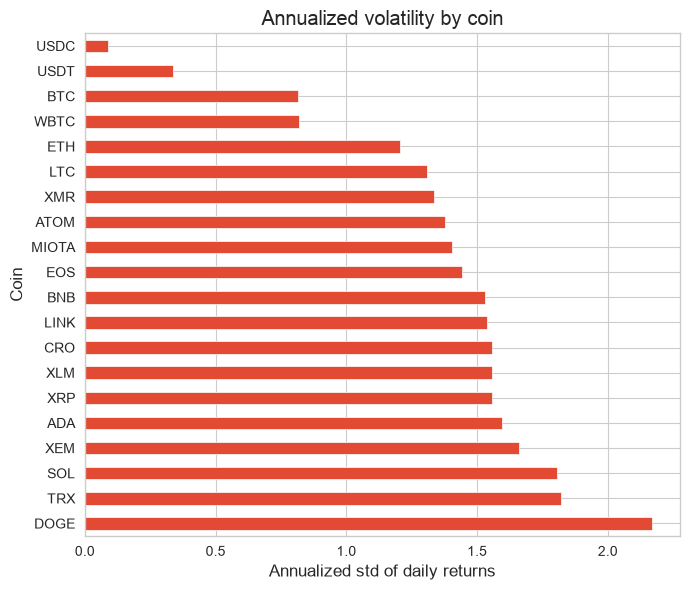

In [13]:
def ann_vol(coin_group):
    """Annualized std of daily returns (sqrt(365) scaling) for one coin's rows."""
    daily_ret = coin_group.sort_values("Date")["Close"].pct_change()
    return daily_ret.std() * np.sqrt(365)

vol = daily.groupby("Symbol").apply(ann_vol, include_groups=False).sort_values(ascending=False)
vol = vol[daily.groupby('Symbol')['Date'].count() > 365]
ax = vol.plot.barh(figsize=(7, 6), title="Annualized volatility by coin")
ax.set_xlabel("Annualized std of daily returns"); ax.set_ylabel("Coin")
plt.tight_layout(); plt.show()

### Are coin returns correlated with each other, or mostly independent?

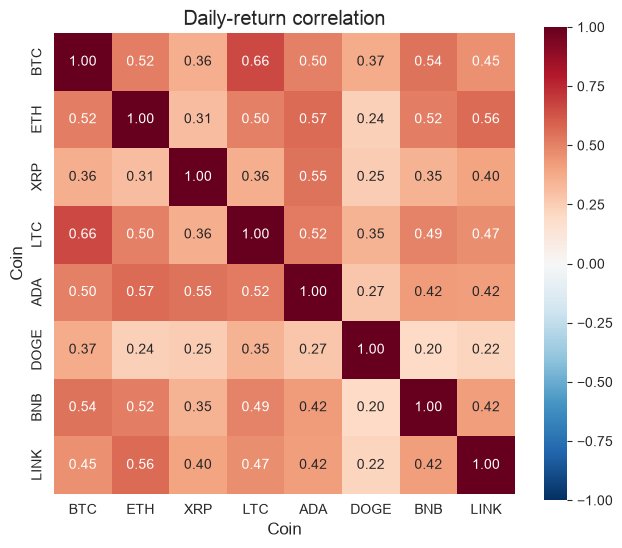

In [14]:
pivot = daily.pivot_table(index="Date", columns="Symbol", values="Close").pct_change()
majors = ["BTC", "ETH", "XRP", "LTC", "ADA", "DOGE", "BNB", "LINK"]
majors = [m for m in majors if m in pivot.columns]
corr = pivot[majors].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, vmin=-1, vmax=1, cmap="RdBu_r", annot=True, fmt=".2f", square=True, ax=ax)
ax.set_xlabel("Coin"); ax.set_ylabel("Coin"); ax.set_title("Daily-return correlation")
plt.tight_layout(); plt.show()


### Is the BTC/ETH correlation statistically significant, or could it be noise?


In [15]:
from scipy.stats import pearsonr

btc_eth = pivot[["BTC", "ETH"]].dropna()
r, p_value = pearsonr(btc_eth["BTC"], btc_eth["ETH"])
print(f"BTC/ETH daily-return correlation: r = {r:.3f}, p-value = {p_value:.2e}, n = {len(btc_eth)} days")
print("-> statistically significant at p<0.05" if p_value < 0.05 else "-> not statistically significant at p<0.05")

BTC/ETH daily-return correlation: r = 0.516, p-value = 6.10e-147, n = 2159 days
-> statistically significant at p<0.05


Most major coins move together with BTC (correlations well above 0 on days when both trade) — consistent with a
market-wide risk factor. This is why the proposal's feature set should probably include a BTC-relative or
market-average momentum term, not just a coin's own history.

The p-value above confirms this isn't a fluke of a small sample — with thousands of days of data, even a moderate correlation like this is extremely unlikely under the null hypothesis of no relationship.

### How do daily return distributions compare across major coins? (seaborn)

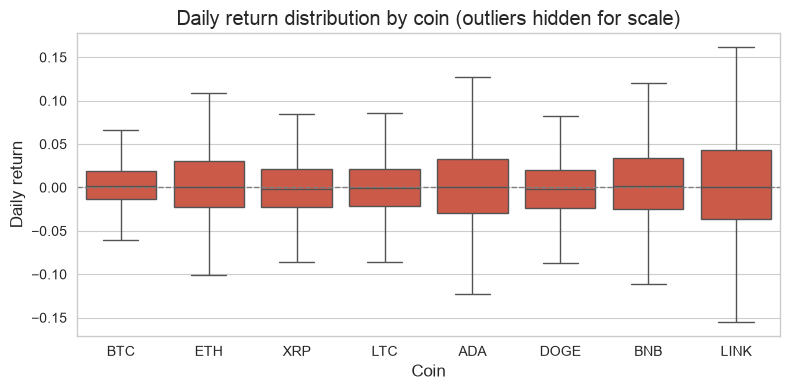

In [16]:
return_by_coin = pivot[majors].melt(var_name="Symbol", value_name="daily_return").dropna()
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=return_by_coin, x="Symbol", y="daily_return", ax=ax, showfliers=False)
ax.set_xlabel("Coin"); ax.set_ylabel("Daily return")
ax.set_title("Daily return distribution by coin (outliers hidden for scale)")
ax.axhline(0, color="gray", ls="--", linewidth=1)
plt.tight_layout(); plt.show()

### Total market capitalization across all 24 coins over time

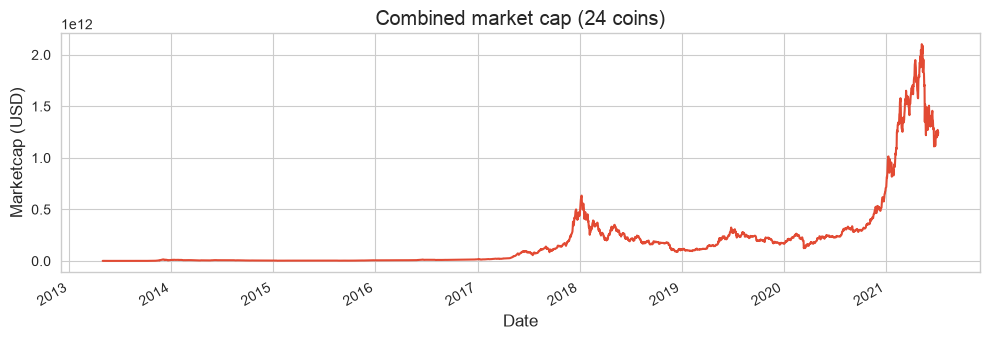

In [17]:
mcap = daily.groupby("Date")["Marketcap"].sum()
plot_ts(mcap, "Combined market cap (24 coins)", "Marketcap (USD)")
plt.show()

### Does trading volume show day-of-week seasonality? (Bitcoin, last 3 years of its history)

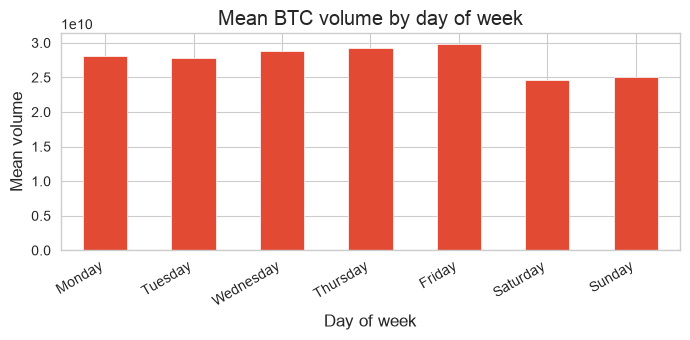

In [18]:
recent = btc.loc[btc.index >= (btc.index.max() - pd.Timedelta(days=3*365))].copy()
recent["dow"] = recent.index.day_name()
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
ax = recent.groupby("dow")["Volume"].mean().reindex(order).plot.bar(figsize=(7, 3.5), title="Mean BTC volume by day of week")
ax.set_xlabel("Day of week"); ax.set_ylabel("Mean volume")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

Unlike traditional equities (which show clear weekday/weekend volume drop-offs because exchanges close), crypto
trades 24/7 — any day-of-week effect here is much weaker, consistent with the proposal's framing in Section 5
("cryptocurrency markets operate 24 hours a day, 7 days a week").

# Part 2 — 15-minute OHLCV series used for modeling

> **`data/coin_price_15min.csv` is a synthetic placeholder**, generated to let the modeling pipeline run end-to-end
> before the real Kaggle "Coin Price Forecasting Challenge" 15-minute file is in place. Everything below describes
> the placeholder, not real market behavior — rerun this section after swapping in the real file.

In [19]:
intraday = pd.read_csv("data/coin_price_15min.csv")
intraday["timestamp"] = pd.to_datetime(intraday["timestamp"])
intraday = intraday.set_index("timestamp").sort_index()
print("Shape:", intraday.shape)
print("Range:", intraday.index.min(), "->", intraday.index.max())
print("Bar spacing (should be 15min):", intraday.index.to_series().diff().mode()[0])
intraday.head()

Shape: (40000, 5)
Range: 2021-01-01 00:00:00 -> 2022-02-21 15:45:00
Bar spacing (should be 15min): 0 days 00:15:00


,open,high,low,close,volume
timestamp,,,,,
2021-01-01 00:00:00,30000.0000,29996.5414,29988.0173,29991.3558,38.1566
2021-01-01 00:15:00,29991.3558,30043.5030,30025.4932,30033.5223,20.0627
2021-01-01 00:30:00,30033.5223,30082.5012,30027.8088,30047.5391,27.2645
2021-01-01 00:45:00,30047.5391,30061.6746,30014.8673,30054.2709,48.4315
2021-01-01 01:00:00,30054.2709,30050.3547,30009.3931,30035.6264,43.9360


### Does the placeholder series look like a believable 24h-return target distribution?

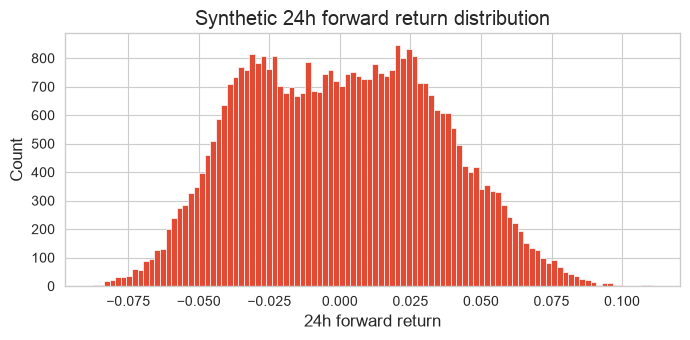

Positive-direction rate: 0.503


In [20]:
fwd_24h = intraday["close"].shift(-96) / intraday["close"] - 1
ax = fwd_24h.dropna().plot.hist(bins=100, figsize=(7, 3.5), title="Synthetic 24h forward return distribution")
ax.set_xlabel("24h forward return"); ax.set_ylabel("Count")
plt.tight_layout(); plt.show()
print("Positive-direction rate:", (fwd_24h.dropna() > 0).mean().round(3))

The placeholder's positive-direction rate sits close to 0.50 by construction (pure random walk plus a weak
injected cycle), unlike Part 1's real coins which show momentum/autocorrelation structure. **This is the key
reason the modeling notebook's ~85% test accuracy on the placeholder should not be trusted** — the synthetic
cycle is far more learnable than real market noise. Re-running both notebooks on the real 15-minute file is a
required next step before drawing any conclusion about the research question.

# Takeaways for feature engineering & modeling
- **Fat tails** in returns (Part 1) → tree ensembles / RNNs are a better fit than linear-Gaussian baselines; consider robust scaling of return features.
- **Cross-coin correlation** is high for major coins → a BTC-relative or market-average momentum feature is likely informative, not just a coin's own lagged returns.
- **Uneven history length** across coins → any multi-coin model needs to handle coins with far less training data (e.g. per-coin normalization, or restrict to coins with 2+ years of history).
- **No strong day-of-week seasonality**, consistent with 24/7 trading — don't expect a simple calendar feature to carry much signal (hour-of-day may still matter and is already in the modeling notebook).
- **The 15-minute series is still synthetic.** Swap in the real Kaggle file (`data/coin_price_15min.csv`) and re-run both this notebook and `crypto_market_prediction.ipynb` before trusting any reported accuracy.